In [1]:
!pip install nltk scikit-learn matplotlib pandas

In [2]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [3]:
data = {
    "review": [

        "I love this product",
        "Amazing quality and fast delivery",
        "The service was excellent",
        "I am very happy with my purchase",
        "This is a wonderful experience",
        "The product works perfectly",
        "Great value for money",
        "I would happily recommend this",
        "The staff were friendly and helpful",
        "I really enjoyed using it",
        "I hate this product",
        "The quality is very poor",
        "Terrible customer service",
        "I am disappointed with this purchase",
        "The delivery was extremely late",
        "This was a waste of money",
        "It stopped working after one day",
        "I will never buy this again",
        "The experience was awful",
        "I regret purchasing this item",
        "The package arrived today",
        "The product is available in blue",
        "I received the order this morning",
        "The box contains two items",
        "The shop opens at nine",
        "The product has three buttons",
        "My order number is 12345",
        "The meeting is scheduled for Monday",
        "The item weighs two kilograms",
        "The store is on the main road"
    ],

    "sentiment": (
        ["Positive"] * 10 +
        ["Negative"] * 10 +
        ["Neutral"] * 10
    )
}

df = pd.DataFrame(data)

df.head()

,review,sentiment
0,I love this product,Positive
1,Amazing quality and fast delivery,Positive
2,The service was excellent,Positive
3,I am very happy with my purchase,Positive
4,This is a wonderful experience,Positive


In [4]:
print("Dataset Shape:", df.shape)
print(df["sentiment"].value_counts())

display(df)

Dataset Shape: (30, 2)
sentiment
Positive    10
Negative    10
Neutral     10
Name: count, dtype: int64


,review,sentiment
0,I love this product,Positive
1,Amazing quality and fast delivery,Positive
2,The service was excellent,Positive
3,I am very happy with my purchase,Positive
4,This is a wonderful experience,Positive
5,The product works perfectly,Positive
6,Great value for money,Positive
7,I would happily recommend this,Positive
8,The staff were friendly and helpful,Positive
9,I really enjoyed using it,Positive


In [5]:
nltk.download('stopwords', quiet=True)
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [6]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
 text = text.lower()
 text = re.sub(r'[^a-z\s]', '', text)
 tokens = word_tokenize(text)
 tokens = [word for word in tokens if word not in stop_words]
 return " ".join(tokens)

df["cleaned_review"] = df["review"].apply(clean_text)

display(df[["review", "cleaned_review"]].head(10))

,review,cleaned_review
0,I love this product,love product
1,Amazing quality and fast delivery,amazing quality fast delivery
2,The service was excellent,service excellent
3,I am very happy with my purchase,happy purchase
4,This is a wonderful experience,wonderful experience
5,The product works perfectly,product works perfectly
6,Great value for money,great value money
7,I would happily recommend this,would happily recommend
8,The staff were friendly and helpful,staff friendly helpful
9,I really enjoyed using it,really enjoyed using


In [7]:
sample_sentence = df.loc[0, "review"]

tokens = word_tokenize(sample_sentence.lower())

print("Original Sentence:", sample_sentence)

print("Tokens:", tokens)

Original Sentence: I love this product
Tokens: ['i', 'love', 'this', 'product']


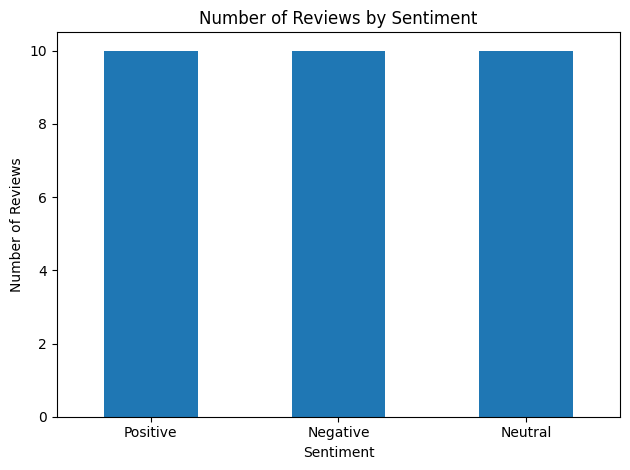

In [8]:
sentiment_counts = df["sentiment"].value_counts()

sentiment_counts.plot(
    kind="bar",
    title="Number of Reviews by Sentiment",
    xlabel="Sentiment",
    ylabel="Number of Reviews",
    rot=0
)

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

In [11]:
X = df["cleaned_review"]
y = df["sentiment"]

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
    )

print("Training Data:", len(X_train_text))
print("Testing Data:", len(X_test_text))

Training Data: 22
Testing Data: 8


In [12]:
vectorizer = CountVectorizer()

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print("Vocabulary:")
print(vectorizer.get_feature_names_out())
print("\nFeature Matrix Shape:")
print(X_train.shape)

Vocabulary:
['arrived' 'available' 'awful' 'blue' 'box' 'buttons' 'contains'
 'customer' 'day' 'disappointed' 'enjoyed' 'excellent' 'experience'
 'friendly' 'great' 'happily' 'happy' 'hate' 'helpful' 'item' 'items'
 'kilograms' 'money' 'nine' 'number' 'one' 'opens' 'order' 'package'
 'perfectly' 'poor' 'product' 'purchase' 'purchasing' 'quality' 'really'
 'recommend' 'regret' 'service' 'shop' 'staff' 'stopped' 'terrible'
 'three' 'today' 'two' 'using' 'value' 'waste' 'weighs' 'working' 'works'
 'would']

Feature Matrix Shape:
(22, 53)


In [13]:
model = MultinomialNB()
model.fit(X_train, y_train)

MultinomialNB()

In [14]:
y_pred = model.predict(X_test)

print("Actual Values:")
print(list(y_test))
print("\nPredicted Values:")
print(list(y_pred))

Actual Values:
['Negative', 'Positive', 'Positive', 'Neutral', 'Positive', 'Neutral', 'Negative', 'Neutral']

Predicted Values:
[np.str_('Negative'), np.str_('Negative'), np.str_('Negative'), np.str_('Neutral'), np.str_('Neutral'), np.str_('Negative'), np.str_('Negative'), np.str_('Negative')]


In [15]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 0.375
Model Accuracy Percentage: 37.5 %


In [16]:
print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

    Negative       0.33      1.00      0.50         2
     Neutral       0.50      0.33      0.40         3
    Positive       0.00      0.00      0.00         3

    accuracy                           0.38         8
   macro avg       0.28      0.44      0.30         8
weighted avg       0.27      0.38      0.28         8



In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Positive", "Negative", "Neutral"]
)

print("Confusion Matrix:\n")
print(cm)

Confusion Matrix:

[[0 2 1]
 [0 2 0]
 [0 2 1]]


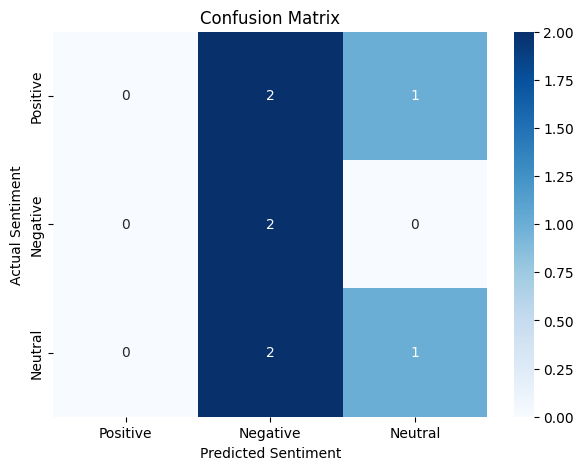

In [18]:
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Positive", "Negative", "Neutral"],
    yticklabels=["Positive", "Negative", "Neutral"]
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.show()

In [19]:
new_reviews = [
    "I really enjoyed this experience",
    "The product is awful",
    "The package arrived this morning",
    "Excellent quality and friendly staff",
    "I will never recommend this product"
]

In [20]:
cleaned_new_reviews = [
    clean_text(review)
    for review in new_reviews
]

print("Cleaned Reviews:\n")
print(cleaned_new_reviews)

Cleaned Reviews:

['really enjoyed experience', 'product awful', 'package arrived morning', 'excellent quality friendly staff', 'never recommend product']


In [21]:
new_features = vectorizer.transform(cleaned_new_reviews)

print("New Feature Matrix:")
print(new_features.shape)

New Feature Matrix:
(5, 53)


In [22]:
predictions = model.predict(new_features)

for review, sentiment in zip(new_reviews, predictions):

    print("Review:", review)
    print("Predicted Sentiment:", sentiment)
    print("-" * 50)

Review: I really enjoyed this experience
Predicted Sentiment: Positive
--------------------------------------------------
Review: The product is awful
Predicted Sentiment: Negative
--------------------------------------------------
Review: The package arrived this morning
Predicted Sentiment: Neutral
--------------------------------------------------
Review: Excellent quality and friendly staff
Predicted Sentiment: Positive
--------------------------------------------------
Review: I will never recommend this product
Predicted Sentiment: Positive
--------------------------------------------------


In [23]:
print("======================================")

print("     SENTIMENT ANALYSIS PROJECT")

print("======================================")

print("Total Reviews:", len(df))

print("Positive Reviews:", (df["sentiment"] == "Positive").sum())

print("Negative Reviews:", (df["sentiment"] == "Negative").sum())

print("Neutral Reviews:", (df["sentiment"] == "Neutral").sum())

print("--------------------------------------")

print("Algorithm: Multinomial Naive Bayes")

print("Feature Extraction: CountVectorizer")

print("Accuracy:", round(accuracy * 100, 2), "%")

print("--------------------------------------")

print("PROJECT COMPLETED SUCCESSFULLY!")

print("======================================")

     SENTIMENT ANALYSIS PROJECT
Total Reviews: 30
Positive Reviews: 10
Negative Reviews: 10
Neutral Reviews: 10
--------------------------------------
Algorithm: Multinomial Naive Bayes
Feature Extraction: CountVectorizer
Accuracy: 37.5 %
--------------------------------------
PROJECT COMPLETED SUCCESSFULLY!
